In [10]:
# Thiết lập môi trường làm việc (tự động phát hiện Google Colab hoặc Local)
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    colab_dir = "/content/drive/MyDrive/ColabNotebooks/Noron&DeepLearning/techtrail-ai-engine-v1"
    if os.path.exists(colab_dir):
        %cd {colab_dir}
except Exception:
    pass

print("Đường dẫn làm việc hiện tại:", os.getcwd())
print("Danh sách file trong data/:", os.listdir('data') if os.path.exists('data') else "Chưa có thư mục data")


Đường dẫn làm việc hiện tại: d:\coding\My AI project\techtrail-ai-engine-v1
Danh sách file trong data/: ['resume-dataset.csv', 'test.csv', 'train.csv', 'val.csv']


## Chia data thành 70-15-15: train-test-validation


In [11]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

os.makedirs("data", exist_ok=True)

train_path = "data/train.csv"
val_path = "data/val.csv"
test_path = "data/test.csv"

FORCE_RE_SPLIT = False

splits_exist = (
    os.path.exists(train_path) and os.path.getsize(train_path) > 0 and
    os.path.exists(val_path) and os.path.getsize(val_path) > 0 and
    os.path.exists(test_path) and os.path.getsize(test_path) > 0
)

if splits_exist and not FORCE_RE_SPLIT:
    print("Phát hiện các file train.csv, val.csv, test.csv đã có sẵn trong data/. Đang tải...")
    train_df = pd.read_csv(train_path)
    val_df = pd.read_csv(val_path)
    test_df = pd.read_csv(test_path)
    
    # Chuẩn hóa bảng ánh xạ Category <-> Label ID từ dữ liệu có sẵn
    if 'category' in train_df.columns and 'label' in train_df.columns:
        cat_label_df = train_df[['category', 'label']].drop_duplicates().sort_values('label')
        category_to_id = dict(zip(cat_label_df['category'], cat_label_df['label']))
        id_to_category = dict(zip(cat_label_df['label'], cat_label_df['category']))
    else:
        unique_categories = sorted(train_df['category'].unique())
        category_to_id = {cat: idx for idx, cat in enumerate(unique_categories)}
        id_to_category = {idx: cat for cat, idx in category_to_id.items()}
        train_df['label'] = train_df['category'].map(category_to_id)
        val_df['label'] = val_df['category'].map(category_to_id)
        test_df['label'] = test_df['category'].map(category_to_id)
    
    print("Đã tải thành công dữ liệu từ các file có sẵn!")

else:
    print("Tiến hành nạp và phân chia lại từ dataset gốc mới nhất (FORCE_RE_SPLIT=True)...\n")
    
    # 1. Nạp file dataset gốc từ thư mục data/
    data_file = 'data/resume-dataset.csv'
    if not (os.path.exists(data_file) and os.path.getsize(data_file) > 0):
        other_csvs = [
            os.path.join('data', f) for f in os.listdir('data')
            if f.endswith('.csv') and not f.startswith(('train', 'val', 'test'))
        ]
        if other_csvs:
            data_file = other_csvs[0]
        else:
            raise FileNotFoundError("Không tìm thấy file dataset gốc nào trong thư mục data/!")

    print(f"Đang đọc dữ liệu từ: {data_file}")
    df = pd.read_csv(data_file)
    print(f"Đã tải {len(df)} dòng dữ liệu từ {data_file}")

    # 2. Chuẩn hóa tên cột
    text_col = None
    for col in ['Resume', 'text_sequence', 'clean_text', 'text', 'resume']:
        if col in df.columns:
            text_col = col
            break
    if text_col is None:
        raise KeyError(f"Không tìm thấy cột văn bản trong các cột: {df.columns.tolist()}")

    cat_col = None
    for col in ['Category', 'category', 'label']:
        if col in df.columns:
            cat_col = col
            break
    if cat_col is None:
        raise KeyError(f"Không tìm thấy cột ngành nghề trong các cột: {df.columns.tolist()}")

    # Ánh xạ nhãn Category thành số nguyên (0..N-1)
    unique_categories = sorted(df[cat_col].unique())
    category_to_id = {cat: idx for idx, cat in enumerate(unique_categories)}
    id_to_category = {idx: cat for cat, idx in category_to_id.items()}

    df['text_sequence'] = df[text_col].astype(str)
    df['category'] = df[cat_col]
    df['label'] = df['category'].map(category_to_id)
    if 'id' not in df.columns:
        df['id'] = df.index
    df = df[['id', 'text_sequence', 'category', 'label']]

    # 3. Chia 70-15-15: train-val-test phân tầng theo nhãn
    train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df['label'])
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['label'])

    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    # Lưu ra file CSV
    train_df.to_csv(train_path, index=False)
    val_df.to_csv(val_path, index=False)
    test_df.to_csv(test_path, index=False)
    print("Đã lưu các file train.csv, val.csv, test.csv vào thư mục data/.")

# 4. In thông tin tổng kết
total_len = len(train_df) + len(val_df) + len(test_df)
print(f"\nKích thước các tập dữ liệu:")
print(f"  Train: {len(train_df)} dòng ({len(train_df)/total_len*100:.1f}%)")
print(f"  Val:   {len(val_df)} dòng ({len(val_df)/total_len*100:.1f}%)")
print(f"  Test:  {len(test_df)} dòng ({len(test_df)/total_len*100:.1f}%)")

print("\nBảng ánh xạ nhãn (Category -> Label ID):")
for cat, idx in sorted(category_to_id.items(), key=lambda x: x[1]):
    print(f"  {idx}: {cat}")


Phát hiện các file train.csv, val.csv, test.csv đã có sẵn trong data/. Đang tải...
Đã tải thành công dữ liệu từ các file có sẵn!

Kích thước các tập dữ liệu:
  Train: 1400 dòng (70.0%)
  Val:   300 dòng (15.0%)
  Test:  300 dòng (15.0%)

Bảng ánh xạ nhãn (Category -> Label ID):
  0: Backend Developer
  1: Cloud Enginee
  2: Data Scientist
  3: Frontend Developer
  4: Full Stack Developer
  5: Machine Learning Engineer
  6: Mobile App Developer (iOS/Android)
  7: Python Developer


### set up

In [12]:
import os, copy, random, time, re
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [13]:
from collections import Counter

# Xây dựng từ điển vocab từ tập train
def build_vocab(texts, min_freq=1):
    word_counts = Counter()
    for text in texts:
        word_counts.update(str(text).split())
    vocab = {'<PAD>': 0, '<UNK>': 1}
    for word, count in word_counts.items():
        if count >= min_freq and word not in vocab:
            vocab[word] = len(vocab)
    return vocab

vocab = build_vocab(train_df['text_sequence'])
print(f"Kích thước từ điển (Vocab size): {len(vocab)} từ")


Kích thước từ điển (Vocab size): 1649 từ


## Thiết lập Loss Function, Optimizer & Vòng lặp Huấn luyện (Training Loop)

- **Loss Function**: `nn.CrossEntropyLoss()` (chuẩn hóa Softmax và tính Negative Log Likelihood Loss).
- **Optimizer**: `Adam(lr=0.002, weight_decay=1e-4)`.
- **Learning Rate Scheduler**: `ReduceLROnPlateau` tự động giảm tốc độ học khi hàm mất mát chững lại.
- **Early Stopping**: Tự động dừng huấn luyện khi Loss trên tập validation không cải thiện sau $N$ epochs, đồng thời lưu trọng số tốt nhất.

In [14]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for batch_x, batch_y in dataloader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        total_loss += loss.item() * batch_x.size(0)
        preds = logits.argmax(dim=1)
        total_correct += (preds == batch_y).sum().item()
        total_samples += batch_x.size(0)

    return total_loss / total_samples, total_correct / total_samples

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            total_loss += loss.item() * batch_x.size(0)
            preds = logits.argmax(dim=1)
            total_correct += (preds == batch_y).sum().item()
            total_samples += batch_x.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch_y.cpu().numpy())

    return total_loss / total_samples, total_correct / total_samples, np.array(all_preds), np.array(all_labels)

## Từ đây là phần dùng dữ liệu mức câu v2

### 7: Chẩn đoán 

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def split_sentences(text):
    """Tách văn bản thành các câu (mỗi câu sẽ là 1 time step của chuỗi)."""
    sents = [s.strip() for s in re.split(r'(?<=[.!?])\s+', str(text).strip()) if s.strip()]
    return sents if sents else [""]

print("Số câu / CV (train):", train_df['text_sequence'].map(lambda t: len(split_sentences(t))).value_counts().sort_index().to_dict())

print("\nAccuracy (val) khi chỉ nhìn câu thứ k:")
for k in range(7):
    pick = lambda t, k=k: (split_sentences(t)[k] if k < len(split_sentences(t)) else "")
    vec = TfidfVectorizer(sublinear_tf=True)
    Xtr = vec.fit_transform(train_df['text_sequence'].map(pick))
    clf = LogisticRegression(max_iter=3000, C=30).fit(Xtr, train_df['label'])
    acc = clf.score(vec.transform(val_df['text_sequence'].map(pick)), val_df['label'])
    print(f"  câu {k}: {acc*100:5.1f}%")

Số câu / CV (train): {6: 106, 7: 654, 8: 640}

Accuracy (val) khi chỉ nhìn câu thứ k:
  câu 0: 100.0%
  câu 1:  46.7%
  câu 2:  21.3%
  câu 3:  25.0%
  câu 4:  40.0%
  câu 5:  28.0%
  câu 6:  20.7%


### 8: tạo dữ liệu dịch vòng câu

In [16]:
def make_shifted(df, seed=42):
    """Dịch vòng (circular shift) các câu của mỗi CV một lượng ngẫu nhiên.
    - Giữ nguyên nội dung và thứ tự tương đối giữa các câu.
    - Câu bằng chứng (câu đầu gốc) bị dời tới vị trí ngẫu nhiên.
    - Lưu evid_pos để kiểm tra Attention có chú ý đúng câu hay không."""
    rng = np.random.RandomState(seed)
    new_texts, evid = [], []
    for t in df['text_sequence']:
        s = split_sentences(t)
        k = rng.randint(len(s))
        new_texts.append(" ".join(s[k:] + s[:k]))
        evid.append((len(s) - k) % len(s))      # vị trí mới của câu đầu gốc
    out = df.copy()
    out['text_sequence'] = new_texts
    out['evid_pos'] = evid
    return out

def keep_original(df):
    out = df.copy(); out['evid_pos'] = 0; return out

v1 = {'train': keep_original(train_df), 'val': keep_original(val_df), 'test': keep_original(test_df)}
v2 = {'train': make_shifted(train_df, 1), 'val': make_shifted(val_df, 2), 'test': make_shifted(test_df, 3)}

print("Phân bố vị trí câu bằng chứng trong test v2:", np.bincount(v2['test']['evid_pos']).tolist())

def first_third(t):
    w = str(t).split(); return " ".join(w[:max(1, len(w)//3)])
for name, d in [('v1', v1), ('v2', v2)]:
    vec = TfidfVectorizer(sublinear_tf=True)
    Xtr = vec.fit_transform(d['train']['text_sequence'].map(first_third))
    clf = LogisticRegression(max_iter=3000, C=30).fit(Xtr, d['train']['label'])
    acc = clf.score(vec.transform(d['val']['text_sequence'].map(first_third)), d['val']['label'])
    print(f"TF-IDF chỉ nhìn 1/3 đầu - {name}: {acc*100:.1f}% (val)")

Phân bố vị trí câu bằng chứng trong test v2: [50, 36, 47, 41, 35, 41, 28, 22]
TF-IDF chỉ nhìn 1/3 đầu - v1: 100.0% (val)
TF-IDF chỉ nhìn 1/3 đầu - v2: 57.3% (val)


### 9: dataset mức câu

In [17]:
MAX_SENTS, MAX_LEN = 8, 64

_lens = [len(s.split()) for t in train_df['text_sequence'] for s in split_sentences(t)]
print(f"Độ dài câu (từ): trung bình={np.mean(_lens):.1f}, p95={np.percentile(_lens,95):.0f}, max={max(_lens)}")

class SentenceDataset(Dataset):
    """Mỗi mẫu: tensor (MAX_SENTS, MAX_LEN) chỉ số từ; 0 = PAD."""
    def __init__(self, df, vocab, permute=False, seed=0):
        rng = np.random.RandomState(seed)
        N = len(df)
        self.X = torch.zeros((N, MAX_SENTS, MAX_LEN), dtype=torch.long)
        self.y = torch.tensor(df['label'].values, dtype=torch.long)
        self.evid = torch.tensor(df['evid_pos'].values, dtype=torch.long)
        unk = vocab.get('<UNK>', 1)
        for i, text in enumerate(df['text_sequence']):
            sents = split_sentences(text)[:MAX_SENTS]
            if permute:                                   # ablation: xáo trộn thứ tự câu
                sents = [sents[j] for j in rng.permutation(len(sents))]
            for si, s in enumerate(sents):
                ids = [vocab.get(w, unk) for w in s.split()][:MAX_LEN]
                self.X[i, si, :len(ids)] = torch.tensor(ids, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

def make_loaders(d, batch_size=32, permute_test=False):
    ds = {k: SentenceDataset(d[k], vocab, permute=(permute_test and k == 'test'), seed=7) for k in d}
    return {
        'train': DataLoader(ds['train'], batch_size=batch_size, shuffle=True),
        'val':   DataLoader(ds['val'],   batch_size=batch_size),
        'test':  DataLoader(ds['test'],  batch_size=batch_size),
        'test_ds': ds['test']}

L1, L2 = make_loaders(v1), make_loaders(v2)
xb, yb = next(iter(L2['train']))
print("Batch X:", tuple(xb.shape), "= (batch, số câu, số từ/câu) | Batch y:", tuple(yb.shape))

Độ dài câu (từ): trung bình=19.4, p95=42, max=65
Batch X: (32, 8, 64) = (batch, số câu, số từ/câu) | Batch y: (32,)


### 10 – Kiến trúc: sentence encoder + BiLSTM + Bahdanau Attention

In [19]:
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim, attn_dim=128):
        super().__init__()
        self.w = nn.Linear(hidden_dim, attn_dim)
        self.v = nn.Linear(attn_dim, 1, bias=False)

    def forward(self, h, mask=None):
        scores = self.v(torch.tanh(self.w(h))).squeeze(-1)
        if mask is not None:
            scores = scores.masked_fill(~mask, -1e9)
        attn_weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(attn_weights.unsqueeze(1), h).squeeze(1)
        return context, attn_weights

In [20]:
class SentenceSeqClassifier(nn.Module):
    """mode: mlp | rnn | gru | lstm | lstm_attn | bilstm | bilstm_attn"""
    def __init__(self, vocab_size, num_classes, mode='bilstm_attn',
                 embed_dim=128, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.mode = mode
        self.use_attn = mode.endswith('_attn')
        base = mode.replace('_attn', '')
        self.bi = base.startswith('bi')
        base = base[2:] if self.bi else base
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.drop = nn.Dropout(dropout)
        if mode == 'mlp':
            self.mlp = nn.Sequential(nn.Linear(embed_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
            out_dim = hidden_dim
        else:
            Cell = {'rnn': nn.RNN, 'gru': nn.GRU, 'lstm': nn.LSTM}[base]
            self.rnn = Cell(embed_dim, hidden_dim, batch_first=True, bidirectional=self.bi)
            out_dim = hidden_dim * (2 if self.bi else 1)
        if self.use_attn:
            self.attn = AdditiveAttention(out_dim)
        self.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(out_dim, num_classes))
        self.last_attn = None

    def encode_sentences(self, x):
        emb = self.embedding(x)
        wmask = (x != 0).unsqueeze(-1).float()
        return self.drop((emb * wmask).sum(2) / wmask.sum(2).clamp(min=1.0))

    def forward(self, x):
        smask = (x != 0).any(dim=2)
        h = self.encode_sentences(x)
        if self.mode == 'mlp':
            m = smask.unsqueeze(-1).float()
            return self.fc(self.mlp((h * m).sum(1) / m.sum(1).clamp(min=1.0)))
        lengths = smask.sum(1).clamp(min=1).cpu()
        packed = pack_padded_sequence(h, lengths, batch_first=True, enforce_sorted=False)
        out, hid = self.rnn(packed)
        if self.use_attn:
            out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
            ctx, a = self.attn(out, smask)
            self.last_attn = a.detach()
            return self.fc(ctx)
        hn = hid[0] if isinstance(hid, tuple) else hid      # RNN/GRU không có cell state
        last = torch.cat([hn[-2], hn[-1]], 1) if self.bi else hn[-1]
        return self.fc(last)

for m in ['mlp', 'rnn', 'gru', 'lstm', 'lstm_attn', 'bilstm', 'bilstm_attn']:
    net = SentenceSeqClassifier(len(vocab), len(category_to_id), mode=m)
    print(f"{m:12s} | tham số: {sum(p.numel() for p in net.parameters() if p.requires_grad):,} | logits:", tuple(net(xb).shape))

mlp          | tham số: 228,616 | logits: (32, 8)
rnn          | tham số: 245,128 | logits: (32, 8)
gru          | tham số: 311,176 | logits: (32, 8)
lstm         | tham số: 344,200 | logits: (32, 8)
lstm_attn    | tham số: 360,840 | logits: (32, 8)
bilstm       | tham số: 477,320 | logits: (32, 8)
bilstm_attn  | tham số: 510,344 | logits: (32, 8)


### 11 – Hàm chạy một thí nghiệm

In [ ]:
from sklearn.metrics import f1_score

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def run_one(mode, loaders, seed, epochs=25, lr=2e-3, hidden=128, dropout=0.3, patience=6,
            weight_decay=1e-4, criterion=None, extra_test=None, eval_test = True):
    set_seed(seed); t0 = time.time()
    crit = criterion or nn.CrossEntropyLoss()
    model = SentenceSeqClassifier(len(vocab), len(category_to_id), mode=mode,
                                  hidden_dim=hidden, dropout=dropout).to(device)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=2)
    best_loss, best_state, bad = float('inf'), copy.deepcopy(model.state_dict()), 0
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for ep in range(epochs):
        tl, ta = train_one_epoch(model, loaders['train'], crit, opt, device)
        vl, va, _, _ = evaluate(model, loaders['val'], crit, device)
        sched.step(vl)
        for k, v in zip(hist, (tl, vl, ta, va)): hist[k].append(v)
        if vl < best_loss:
            best_loss, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    res = {'mode': mode, 'seed': seed, 'params': sum(p.numel() for p in model.parameters() if p.requires_grad),
           'epochs': len(hist['val_loss']), 'best_val_loss': best_loss, 'train_time': time.time() - t0}
    if eval_test:
        _, acc, preds, labels = evaluate(model, loaders['test'], crit, device)
        res.update(test_acc=acc, macro_f1=f1_score(labels, preds, average='macro'), preds=preds, labels=labels)
        if extra_test is not None:
            _, res['test_acc_shuffled'], _, _ = evaluate(model, extra_test, crit, device)
    return model, hist, res

t0 = time.time()
_, _, r = run_one('bilstm_attn', L2, seed=0)
print(f"Thử nhanh BiLSTM+Attention (v2): test acc = {r['test_acc']*100:.2f}% | macro-F1 = {r['macro_f1']:.4f} | {time.time()-t0:.1f}s")

Thử nhanh BiLSTM+Attention (v2): test acc = 98.33% | macro-F1 = 0.9834 | 14.7s


### Cell 12 – Bảng so sánh chính

In [28]:
SEEDS = [0, 1, 2, 3, 4]
MODES = ['mlp', 'rnn', 'gru', 'lstm', 'lstm_attn', 'bilstm', 'bilstm_attn']
L1s = make_loaders(v1, permute_test=True)
L2s = make_loaders(v2, permute_test=True)

rows, store, preds_store, hist_store = [], {}, {}, {}
for ver, L, Ls in [('v1 (bằng chứng ở câu đầu)', L1, L1s), ('v2 (vị trí ngẫu nhiên)', L2, L2s)]:
    for mode in MODES:
        for seed in SEEDS:
            model, hist, r = run_one(mode, L, seed, extra_test=Ls['test'])
            hist_store[(ver, mode, seed)] = hist
            if mode == 'bilstm_attn':
                store[(ver, seed)] = (model, hist)
                preds_store[(ver, seed)] = (r['preds'], r['labels'])
            rows.append({'data': ver, 'model': mode, 'seed': seed, 'acc': r['test_acc'],
                         'f1': r['macro_f1'], 'acc_shuffled': r['test_acc_shuffled'], 'params': r['params'], 'time': r['train_time']})
        print(f"xong {ver} / {mode}")

res = pd.DataFrame(rows)
summary = res.groupby(['data', 'model']).agg(
    acc_mean=('acc', 'mean'), acc_std=('acc', 'std'),
    f1_mean=('f1', 'mean'), f1_std=('f1', 'std'),
    acc_shuffled=('acc_shuffled', 'mean'), params=('params', 'first')).reindex(
    pd.MultiIndex.from_product([res['data'].unique(), MODES]))
summary['Accuracy %'] = (summary.acc_mean*100).round(2).astype(str) + ' ± ' + (summary.acc_std*100).round(2).astype(str)
summary['Macro-F1'] = summary.f1_mean.round(4).astype(str) + ' ± ' + summary.f1_std.round(4).astype(str)
summary['Acc khi xáo câu %'] = (summary.acc_shuffled*100).round(2)
os.makedirs('results', exist_ok=True)
res.to_csv('results/runs_all.csv', index=False)
summary.to_csv('results/summary_table.csv')
summary[['Accuracy %', 'Macro-F1', 'Acc khi xáo câu %', 'params']]

xong v1 (bằng chứng ở câu đầu) / mlp
xong v1 (bằng chứng ở câu đầu) / rnn
xong v1 (bằng chứng ở câu đầu) / gru
xong v1 (bằng chứng ở câu đầu) / lstm
xong v1 (bằng chứng ở câu đầu) / lstm_attn
xong v1 (bằng chứng ở câu đầu) / bilstm
xong v1 (bằng chứng ở câu đầu) / bilstm_attn
xong v2 (vị trí ngẫu nhiên) / mlp
xong v2 (vị trí ngẫu nhiên) / rnn
xong v2 (vị trí ngẫu nhiên) / gru
xong v2 (vị trí ngẫu nhiên) / lstm
xong v2 (vị trí ngẫu nhiên) / lstm_attn
xong v2 (vị trí ngẫu nhiên) / bilstm
xong v2 (vị trí ngẫu nhiên) / bilstm_attn


Accuracy %         Macro-F1  \
v1 (bằng chứng ở câu đầu) mlp          86.13 ± 0.69  0.8612 ± 0.0074   
                          rnn          98.53 ± 0.84  0.9853 ± 0.0085   
                          gru            98.6 ± 0.6    0.986 ± 0.006   
                          lstm         98.87 ± 0.61  0.9887 ± 0.0061   
                          lstm_attn    98.27 ± 1.46  0.9826 ± 0.0146   
                          bilstm       99.33 ± 0.33  0.9933 ± 0.0033   
                          bilstm_attn   99.2 ± 0.69   0.992 ± 0.0069   
v2 (vị trí ngẫu nhiên)    mlp          85.87 ± 0.96  0.8579 ± 0.0096   
                          rnn          82.93 ± 1.16  0.8283 ± 0.0114   
                          gru           96.0 ± 1.13  0.9599 ± 0.0114   
                          lstm         93.47 ± 2.43  0.9343 ± 0.0245   
                          lstm_attn    94.53 ± 0.69  0.9453 ± 0.0068   
                          bilstm        90.6 ± 2.35  0.9064 ± 0.0234   
                          bilstm_attn  98.67 ± 0.33  0.9867 ± 0.0034   

                                       Acc khi xáo câu %  params  
v1 (bằng chứng ở câu đầu) mlp                      86.13  228616  
                          rnn                      49.33  245128  
                          gru                      58.80  311176  
                          lstm                     58.53  344200  
                          lstm_attn                54.60  360840  
                          bilstm                   64.27  477320  
                          bilstm_attn              55.53  510344  
v2 (vị trí ngẫu nhiên)    mlp                      85.87  228616  
                          rnn                      82.53  245128  
                          gru                      83.67  311176  
                          lstm                     84.60  344200  
                          lstm_attn                83.60  360840  
                          bilstm                   85.13  477320  
                          bilstm_attn              84.80  510344

### Cell 13 – Learning curve

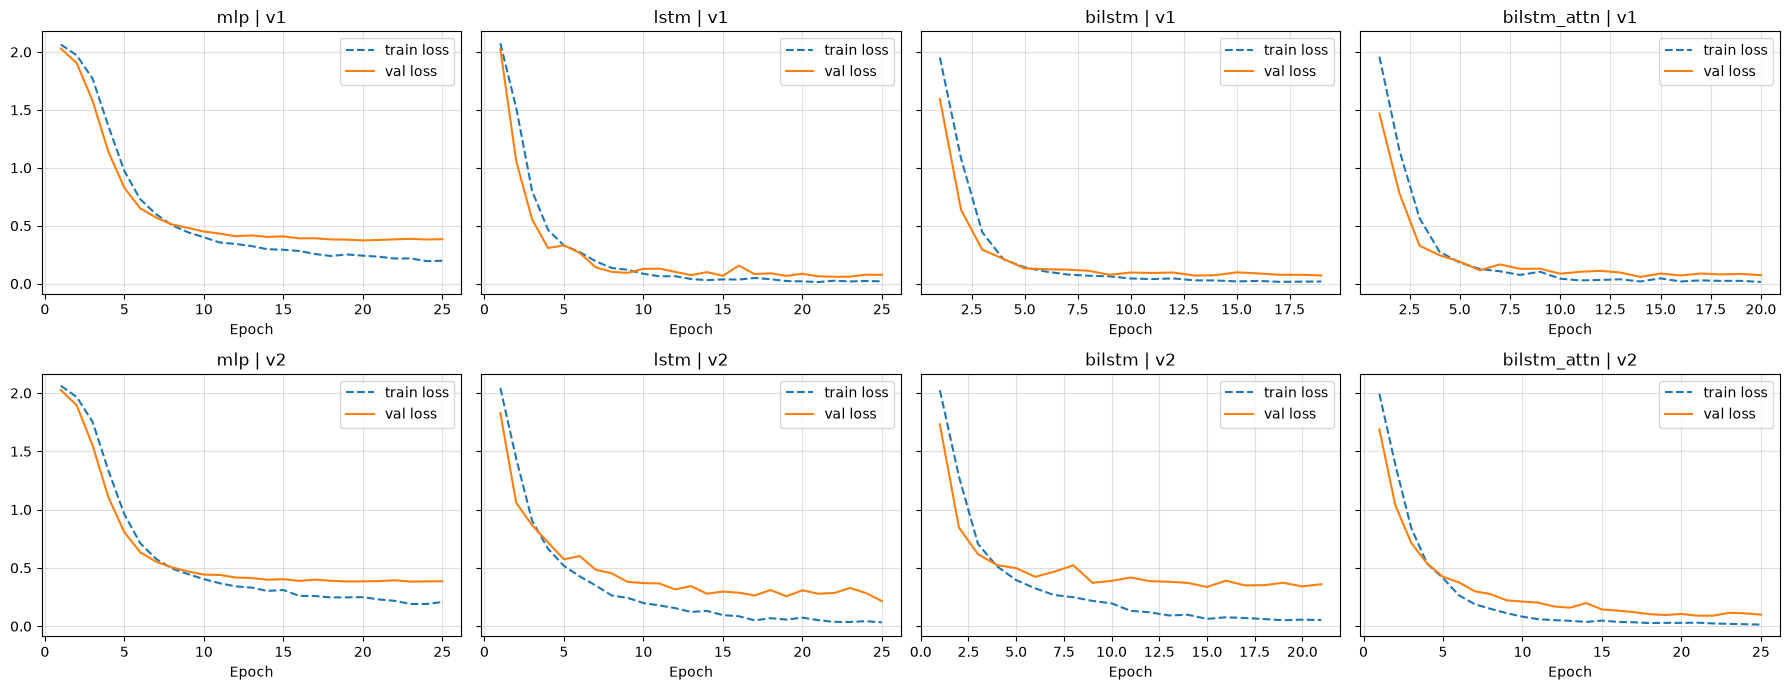

epoch_dừng  epoch_tốt_nhất  train_loss  val_loss  train_acc  \
data model                                                                      
v1   mlp                24.6            21.2      0.2268    0.3732     0.9243   
     rnn                25.0            22.8      0.0462    0.0608     0.9876   
     gru                24.4            21.4      0.0174    0.0466     0.9963   
     lstm               25.0            23.2      0.0205    0.0483     0.9946   
     lstm_attn          20.0            15.2      0.0489    0.0362     0.9861   
     bilstm             23.0            19.4      0.0189    0.0480     0.9954   
     bilstm_attn        21.6            15.6      0.0274    0.0328     0.9933   
v2   mlp                24.4            20.8      0.2271    0.3783     0.9234   
     rnn                20.0            14.0      0.2046    0.4250     0.9294   
     gru                24.2            19.4      0.0267    0.1168     0.9954   
     lstm               24.6            22.0      0.0480    0.2185     0.9869   
     lstm_attn          24.2            20.2      0.0414    0.1822     0.9899   
     bilstm             22.2            18.0      0.0691    0.3159     0.9777   
     bilstm_attn        25.0            22.4      0.0216    0.0721     0.9974   

                  val_acc  gap_loss  gap_acc  
data model                                    
v1   mlp           0.8633    0.1464   0.0610  
     rnn           0.9780    0.0146   0.0096  
     gru           0.9847    0.0292   0.0116  
     lstm          0.9833    0.0278   0.0113  
     lstm_attn     0.9853   -0.0127   0.0008  
     bilstm        0.9847    0.0291   0.0107  
     bilstm_attn   0.9900    0.0054   0.0033  
v2   mlp           0.8593    0.1512   0.0641  
     rnn           0.8420    0.2204   0.0874  
     gru           0.9567    0.0901   0.0387  
     lstm          0.9300    0.1705   0.0569  
     lstm_attn     0.9407    0.1408   0.0492  
     bilstm        0.8993    0.2468   0.0784  
     bilstm_attn   0.9760    0.0505   0.0214

In [29]:
os.makedirs('results', exist_ok=True)
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey='row')
vers = ['v1 (bằng chứng ở câu đầu)', 'v2 (vị trí ngẫu nhiên)']
for i, ver in enumerate(vers):
    for j, mode in enumerate(['mlp', 'lstm', 'bilstm', 'bilstm_attn']):
        h = hist_store[(ver, mode, 0)]
        ep = range(1, len(h['train_loss']) + 1)
        ax = axes[i, j]
        ax.plot(ep, h['train_loss'], '--', label='train loss')
        ax.plot(ep, h['val_loss'], '-', label='val loss')
        ax.set_title(f'{mode} | {ver[:2]}'); ax.set_xlabel('Epoch'); ax.grid(alpha=.4); ax.legend()
plt.tight_layout(); plt.savefig('results/overfit_loss_curves.png', dpi=200); plt.show()

gap = []
for (ver, mode, seed), h in hist_store.items():
    b = int(np.argmin(h['val_loss']))
    gap.append({'data': ver[:2], 'model': mode, 'epoch_dừng': len(h['val_loss']), 'epoch_tốt_nhất': b + 1,
                'train_loss': h['train_loss'][b], 'val_loss': h['val_loss'][b],
                'train_acc': h['train_acc'][b], 'val_acc': h['val_acc'][b]})
gap = pd.DataFrame(gap).groupby(['data', 'model'], sort=False).mean().round(4)
gap['gap_loss'] = (gap.val_loss - gap.train_loss).round(4)
gap['gap_acc'] = (gap.train_acc - gap.val_acc).round(4)
gap.to_csv('results/overfit_gap.csv'); gap

### 14 – Trực quan hóa Attention và kiểm tra định lượng

Attention lên câu bằng chứng: 0.987 ± 0.002
Top-1 đúng câu bằng chứng: 99.7% ± 0.2%
Mức ngẫu nhiên (1/số câu): 0.137


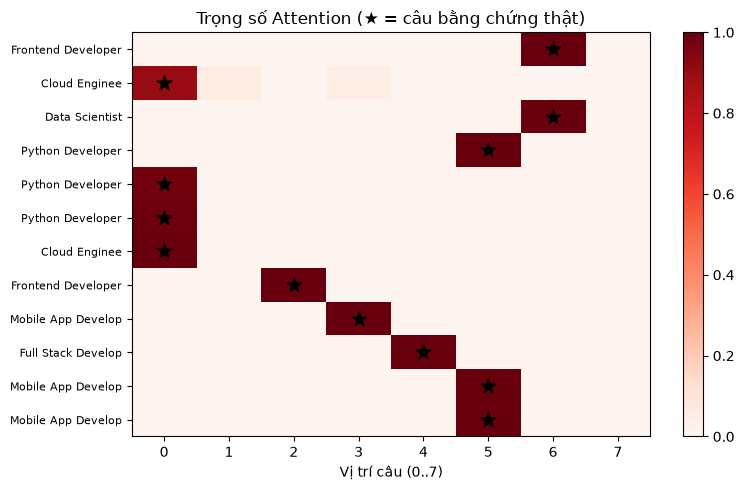

In [30]:
def attention_on_test(model, loader):
    model.eval(); A, P, Y = [], [], []
    with torch.no_grad():
        for xb_, yb_ in loader:
            logits = model(xb_.to(device))
            A.append(model.last_attn.cpu()); P.append(logits.argmax(1).cpu()); Y.append(yb_)
    return torch.cat(A).numpy(), torch.cat(P).numpy(), torch.cat(Y).numpy()

ver = 'v2 (vị trí ngẫu nhiên)'
evid = L2['test_ds'].evid.numpy()
att_model, _ = store[(ver, 0)]
n_sents = np.array([min(len(split_sentences(t)), MAX_SENTS) for t in v2['test']['text_sequence']])

mass_all, top1_all = [], []
for seed in SEEDS:
    att_model, _ = store[(ver, seed)]
    A_s, _, _ = attention_on_test(att_model, L2['test'])
    mass_all.append(A_s[np.arange(len(A_s)), evid].mean())
    top1_all.append((A_s.argmax(1) == evid).mean())
att_model, _ = store[(ver, 0)]
A, P, Y = attention_on_test(att_model, L2['test'])

print(f"Attention lên câu bằng chứng: {np.mean(mass_all):.3f} ± {np.std(mass_all):.3f}")
print(f"Top-1 đúng câu bằng chứng: {np.mean(top1_all)*100:.1f}% ± {np.std(top1_all)*100:.1f}%")
print(f"Mức ngẫu nhiên (1/số câu): {(1/n_sents).mean():.3f}")

n = 12
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(A[:n], aspect='auto', cmap='Reds', vmin=0, vmax=1)
for i in range(n):
    ax.scatter(evid[i], i, marker='*', s=120, color='black')       # câu bằng chứng thật
ax.set_yticks(range(n)); 
ax.set_yticklabels([id_to_category[Y[i]][:18] for i in range(n)], fontsize=8)
ax.set_xlabel('Vị trí câu (0..7)'); 
ax.set_title('Trọng số Attention (★ = câu bằng chứng thật)')
plt.colorbar(im); plt.tight_layout(); 
plt.savefig('results/attention_heatmap.png', dpi=200); 
plt.show()


### 15 – Confusion matrix và phân tích lỗi

                                    precision    recall  f1-score   support

                 Backend Developer     1.0000    0.9730    0.9863        37
                     Cloud Enginee     1.0000    1.0000    1.0000        37
                    Data Scientist     0.9744    1.0000    0.9870        38
                Frontend Developer     0.9737    0.9737    0.9737        38
              Full Stack Developer     0.9487    0.9737    0.9610        38
         Machine Learning Engineer     1.0000    0.9730    0.9863        37
Mobile App Developer (iOS/Android)     1.0000    1.0000    1.0000        38
                  Python Developer     0.9730    0.9730    0.9730        37

                          accuracy                         0.9833       300
                         macro avg     0.9837    0.9833    0.9834       300
                      weighted avg     0.9836    0.9833    0.9834       300



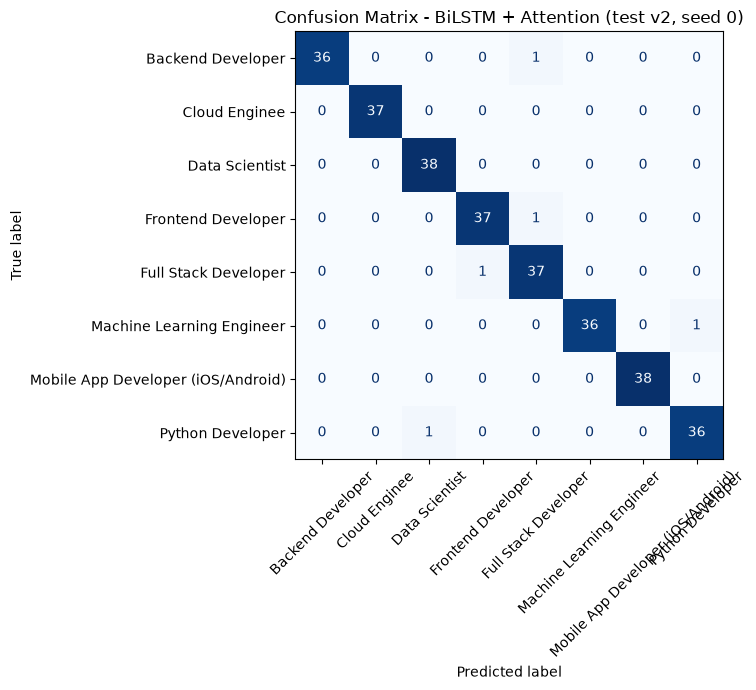

Số mẫu sai: 5/300
Cặp nhầm lẫn nhiều nhất (số mẫu, thật -> dự đoán): [(1, 'Python Developer', 'Data Scientist'), (1, 'Machine Learning Engineer', 'Python Developer'), (1, 'Full Stack Developer', 'Frontend Developer'), (1, 'Frontend Developer', 'Full Stack Developer'), (1, 'Backend Developer', 'Full Stack Developer')]
[Backend Developer -> Full Stack Developer] câu chú ý nhất (0.99): During a project involving a food delivery application, the feature was built end-to-end, from schema design to the final interactive UI, with Postgre
[Machine Learning Engineer -> Python Developer] câu chú ý nhất (1.00): Joining a small startup team midway through the development of a fintech platform, an ETL pipeline was written to standardize and validate incoming lo
[Python Developer -> Data Scientist] câu chú ý nhất (0.91): In an effort to rebuild parts of a media streaming service, data from three separate vendors needed to be reconciled before analysis.
[Frontend Developer -> Full Stack Developer] câ

In [31]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
names = [id_to_category[i] for i in range(len(category_to_id))]
print(classification_report(Y, P, target_names=names, digits=4))

cm = confusion_matrix(Y, P)
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
ax.set_title('Confusion Matrix - BiLSTM + Attention (test v2, seed 0)')
plt.tight_layout(); plt.savefig('results/attn_confusion_matrix.png', dpi=200); plt.show()

# Cặp nhãn bị nhầm nhiều nhất
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = sorted([(int(cm_off[i, j]), names[i], names[j]) for i in range(len(names)) for j in range(len(names)) if cm_off[i, j] > 0], reverse=True)
print(f"Số mẫu sai: {(P != Y).sum()}/{len(Y)}")
print("Cặp nhầm lẫn nhiều nhất (số mẫu, thật -> dự đoán):", pairs[:5])

# 
# câu được attention chú ý nhiều nhất
test_texts = v2['test']['text_sequence'].reset_index(drop=True)
for i in np.where(P != Y)[0]:
    sents = split_sentences(test_texts[i])[:MAX_SENTS]
    j = A[i].argmax()
    attended_text = sents[j][:150] if j < len(sents) else f"[Padding #{j}]"
    print(f"[{id_to_category[Y[i]]} -> {id_to_category[P[i]]}] câu chú ý nhất ({A[i, j]:.2f}): {attended_text}")